# 🍅 Tomato Leaf Disease Detection Model and Prediction Test
# Submitted by:
#   2221081090 - MD. ASHRAFUL ALAM SOHAN
#   2221081094 - MD. ABU SAIM
#   2221081103 - MD. SIYAM KHAN

# Training Model (Step 1 - 8)

In [ ]:
# ✅ STEP 1: Setup Kaggle API
from google.colab import files
files.upload()  # Upload kaggle.json

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json


In [ ]:
# ✅ STEP 2: Install dependencies
!pip install kaggle tensorflow opencv-python matplotlib tqdm scikit-learn

In [ ]:
# ✅ STEP 3: Download Tomato Leaf Dataset from Kaggle
!kaggle datasets download -d charuchaudhry/plantvillage-tomato-leaf-dataset --unzip -p raw_data

Dataset URL: https://www.kaggle.com/datasets/charuchaudhry/plantvillage-tomato-leaf-dataset
License(s): unknown
 96% 427M/443M [00:02<00:00, 174MB/s]
100% 443M/443M [00:05<00:00, 88.2MB/s]


In [ ]:
# ✅ STEP 4: Preprocessing and Augmentation
import os
import cv2
import numpy as np
from tqdm import tqdm
import random
from shutil import rmtree
import matplotlib.pyplot as plt

# Utility: Preprocess and augment image
def preprocess_image(image_path, target_size=(224, 224)):
    img = cv2.imread(image_path)
    if img is None:
        return None
    img = cv2.resize(img, target_size)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = img / 255.0
    return img

def augment_image(img):
    flipped = cv2.flip(img, 1)
    rows, cols, _ = img.shape
    M = cv2.getRotationMatrix2D((cols/2, rows/2), random.choice([-10, 10]), 1)
    rotated = cv2.warpAffine(img, M, (cols, rows))
    noise = np.random.normal(0, 0.05, img.shape)
    noisy = np.clip(img + noise, 0., 1.)
    return [img, flipped, rotated, noisy]

def preprocess_dataset(input_dir="raw_data/plantvillage/plantvillage", output_dir="data", split_ratio=0.8):
    if os.path.exists(output_dir):
        rmtree(output_dir)
    os.makedirs(f"{output_dir}/train", exist_ok=True)
    os.makedirs(f"{output_dir}/val", exist_ok=True)

    total_images = 0
    processed_images = 0

    for cls in os.listdir(input_dir):
        input_path = os.path.join(input_dir, cls)
        if not os.path.isdir(input_path):
            continue
        images = os.listdir(input_path)
        total_images += len(images)
        random.shuffle(images)
        split = int(split_ratio * len(images))
        train_images = images[:split]
        val_images = images[split:]

        for subset, img_list in zip(["train", "val"], [train_images, val_images]):
            os.makedirs(f"{output_dir}/{subset}/{cls}", exist_ok=True)
            for img_name in tqdm(img_list, desc=f"{subset}/{cls}"):
                img_path = os.path.join(input_path, img_name)
                img = preprocess_image(img_path)
                if img is None:
                    continue
                for i, aug in enumerate(augment_image(img)):
                    save_path = os.path.join(output_dir, subset, cls, f"{img_name.split('.')[0]}_aug{i}.jpg")
                    cv2.imwrite(save_path, (aug * 255).astype(np.uint8))
                    processed_images += 1

    print(f"\nTotal original images found: {total_images}")
    print(f"Total augmented images saved: {processed_images}")

preprocess_dataset()

val/Tomato___healthy: 100%|██████████| 255/255 [00:03<00:00, 83.22it/s]
train/Tomato___Spider_mites Two-spotted_spider_mite: 100%|██████████| 1072/1072 [00:13<00:00, 78.11it/s]
val/Tomato___Spider_mites Two-spotted_spider_mite: 100%|██████████| 269/269 [00:04<00:00, 65.62it/s]
val/Tomato___Tomato_mosaic_virus: 100%|██████████| 60/60 [00:00<00:00, 81.88it/s]


Total original images found: 14529
Total augmented images saved: 58116


In [ ]:
# ✅ STEP 5: Build and Train CNN (MobileNetV2)
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense
from sklearn.utils import class_weight
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

img_size = 224
batch_size = 32
train_dir = 'data/train'
val_dir = 'data/val'

total_classes = len(os.listdir(train_dir))

train_datagen = ImageDataGenerator()
val_datagen = ImageDataGenerator()

train_data = train_datagen.flow_from_directory(train_dir, target_size=(img_size, img_size), batch_size=batch_size, class_mode='categorical')
val_data = val_datagen.flow_from_directory(val_dir, target_size=(img_size, img_size), batch_size=batch_size, class_mode='categorical', shuffle=False)

# Compute class weights
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_data.classes),
    y=train_data.classes
)
class_weights = dict(enumerate(class_weights))
print("Class weights:", class_weights)

# Fine-tune: Unfreeze the last 20 layers of the base model
base_model = MobileNetV2(input_shape=(img_size, img_size, 3), include_top=False, weights='imagenet')
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dropout(0.3),
    Dense(total_classes, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

history = model.fit(train_data, validation_data=val_data, epochs=10, class_weight=class_weights)

Found 46472 images belonging to 10 classes.
Found 11644 images belonging to 10 classes.
Class weights: {0: np.float64(0.8536370315944158), 1: np.float64(1.8153125), 2: np.float64(0.9515151515151515), 3: np.float64(1.9108552631578948), 4: np.float64(1.0254192409532215), 5: np.float64(1.083768656716418), 6: np.float64(1.2937639198218263), 7: np.float64(0.33891481913652277), 8: np.float64(4.861087866108787), 9: np.float64(1.1412573673870334)}
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 1,218,890 (4.65 MB)

 Non-trainable params: 1,051,904 (4.01 MB)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
1453/1453 ━━━━━━━━━━━━━━━━━━━━ 3156s 2s/step - accuracy: 0.6960 - loss: 0.8980 - val_accuracy: 0.3538 - val_loss: 7.3965
Epoch 2/10
1453/1453 ━━━━━━━━━━━━━━━━━━━━ 3228s 2s/step - accuracy: 0.8490 - loss: 0.4208 - val_accuracy: 0.6219 - val_loss: 2.7115
Epoch 3/10
1453/1453 ━━━━━━━━━━━━━━━━━━━━ 3139s 2s/step - accuracy: 0.8843 - loss: 0.3200 - val_accuracy: 0.7406 - val_loss: 1.4520
Epoch 4/10
1453/1453 ━━━━━━━━━━━━━━━━━━━━ 3054s 2s/step - accuracy: 0.9038 - loss: 0.2575 - val_accuracy: 0.8075 - val_loss: 1.1638
Epoch 5/10
1453/1453 ━━━━━━━━━━━━━━━━━━━━ 3122s 2s/step - accuracy: 0.9197 - loss: 0.2221 - val_accuracy: 0.6844 - val_loss: 1.7016
Epoch 6/10
1453/1453 ━━━━━━━━━━━━━━━━━━━━ 3081s 2s/step - accuracy: 0.9306 - loss: 0.1882 - val_accuracy: 0.8038 - val_loss: 0.9935
Epoch 7/10
1453/1453 ━━━━━━━━━━━━━━━━━━━━ 3094s 2s/step - accuracy: 0.9404 - loss: 0.1571 - val_accuracy: 0.7828 - val_loss: 1.1802
Epoch 8/10
1453/1453 ━━━━━━━━━━━━━━━━━━━━ 3070s 2s/step - accuracy: 0.9484 -

364/364 ━━━━━━━━━━━━━━━━━━━━ 532s 1s/step

Classification Report:

                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot       0.96      0.86      0.91      1364
                        Tomato___Early_blight       0.82      0.57      0.68       640
                         Tomato___Late_blight       0.96      0.68      0.80      1224
                           Tomato___Leaf_Mold       0.80      0.91      0.85       612
                  Tomato___Septoria_leaf_spot       0.81      0.80      0.80      1136
Tomato___Spider_mites Two-spotted_spider_mite       0.92      0.68      0.78      1076
                         Tomato___Target_Spot       0.50      0.98      0.66       900
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.93      0.94      0.94      3432
                 Tomato___Tomato_mosaic_virus       0.74      0.95      0.83       240
                             Tomato___healthy       0.97      

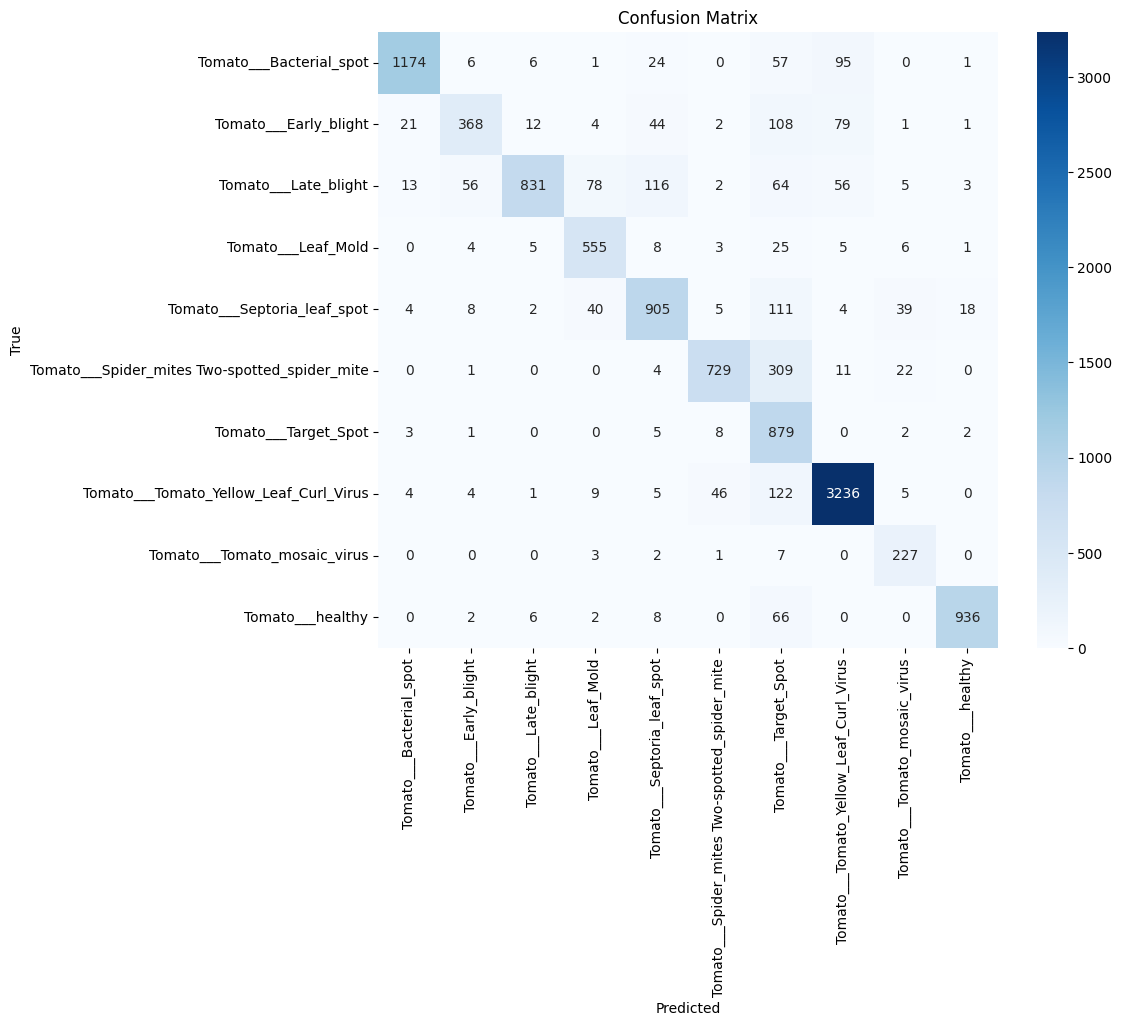

In [ ]:
# ✅ STEP 6: Confusion Matrix and Classification Report
val_preds = model.predict(val_data)
y_pred = np.argmax(val_preds, axis=1)
y_true = val_data.classes

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=list(val_data.class_indices.keys())))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=val_data.class_indices.keys(), yticklabels=val_data.class_indices.keys(), cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

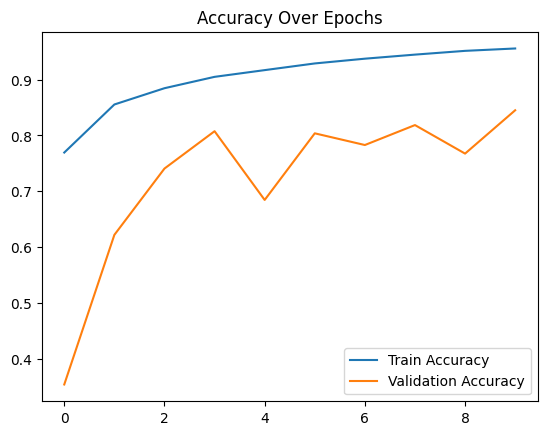

In [ ]:
# ✅ STEP 7: Evaluate and Save Model
import keras
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title("Accuracy Over Epochs")
plt.show()

keras.saving.save_model(model, 'leaf_disease_model_V2.keras')

In [2]:
# ✅ Step 8: Saving to Google drive
!ls -lh
from google.colab import drive
drive.mount('/content/drive')
!cp leaf_disease_model_V2.keras /content/drive/MyDrive/Colab\ Notebooks

total 4.0K
drwxr-xr-x 1 root root 4.0K May 12 13:37 sample_data
Mounted at /content/drive
cp: cannot stat 'leaf_disease_model_V2.keras': No such file or directory


# Prediction using samples (Step 9 - 13)

In [1]:
# ✅ STEP 9: Import Libraries
from tensorflow.keras.models import load_model
import numpy as np
import cv2
import os

# When we want to display images
import matplotlib.pyplot as plt

In [3]:
# ✅ STEP 10: Load the Trained Model
# Update this path to point to your saved model file
model_path = '/content/drive/MyDrive/Colab Notebooks/leaf_disease_model_V2.keras'
model = load_model(model_path)

In [4]:
# ✅ STEP 11: Load and Preprocess an Image for Prediction

def preprocess_image(image_path, target_size=(224, 224)):
    img = cv2.imread(image_path)
    if img is None:
        raise ValueError("Image not found or invalid format.")
    img = cv2.resize(img, target_size)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = img / 255.0  # Normalize
    img = np.expand_dims(img, axis=0)  # Add batch dimension
    return img

In [5]:
# ✅ STEP 12: Upload a Test Image from local computer
#from google.colab import files
#uploaded = files.upload()

# Grab the uploaded filename
#for filename in uploaded.keys():
#    test_image_path = filename
#    break


# ✅ STEP 5 (Alternative): Upload a Test Image from Google drive
test_image_path = "/content/drive/MyDrive/Colab Notebooks/my_leaf2.jpg"

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 918ms/step
Predicted Disease: Tomato___Late_blight
Confidence: 82.28%


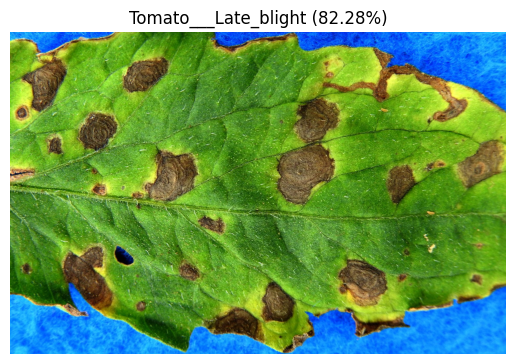

In [6]:
# ✅ STEP 13: Predict and Show Result

# Set the class names based on your training
class_names = ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight',
               'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite',
               'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus',
               'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']

# Preprocess and predict
img = preprocess_image(test_image_path)
pred = model.predict(img)
predicted_class_index = np.argmax(pred)
predicted_class_name = class_names[predicted_class_index]
confidence = np.max(pred) * 100

# Output
print(f"Predicted Disease: {predicted_class_name}")
print(f"Confidence: {confidence:.2f}%")

# Optional: Show image
plt.imshow(cv2.imread(test_image_path)[..., ::-1])
plt.title(f"{predicted_class_name} ({confidence:.2f}%)")
plt.axis('off')
plt.show()